# Replikasi BRFSS 2023 - Explainable ML Diabetes

**Paper acuan:** Muhammad, M. A., Sani, J., & Ahmed, M. M. (2025). *Exploring Explainable Machine Learning for Predicting and Interpreting Self-Reported Diabetes among Tennessee Adults: Insights from the 2023 Behavioral Risk Factor Surveillance System (BRFSS).* Journal of Primary Care & Community Health, 16. https://doi.org/10.1177/21501319251400546

**Tujuan replikasi:** mereproduksi alur paper pada BRFSS 2023 nasional: 80:20 stratified holdout -> preprocessing kategorikal -> SMOTE hanya pada train -> 7 model -> evaluasi -> SHAP.

> Perbedaan scope: paper asli memakai sub-sampel Tennessee (n=5.634). CSV publik yang dapat diunduh ulang pada notebook ini adalah BRFSS 2023 nasional. Agar seluruh tujuh model, termasuk SVM, tetap selesai dijalankan pada skala yang setara paper, cohort final diambil sebagai sampel stratified deterministik n=5.634. Notebook mereplikasi pipeline, bukan angka persis paper.
>
> Catatan replikasi: paper tidak merilis notebook/kode sumber. Notebook ini adalah implementasi independen berdasarkan metode yang tertulis. Paper menyatakan respons `DIABETE4=1` dan `2` sebagai positif; `3` dan `4` sebagai negatif. Konvensi ini dipertahankan agar sesuai acuan, walau `2` adalah gestational-only diabetes.

## 1. Import

In [1]:
from pathlib import Path
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score, average_precision_score,
                             RocCurveDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

## 2. Data Collecting

In [2]:
DATA_FILE = Path("brfss_2023_selected.csv")
VARIABLES = [
    "DIABETE4", "SEXVAR", "_RACE", "_AGEG5YR", "EDUCA", "_INCOMG1", "INCOME3", "EMPLOY1", "MARITAL",
    "_BMI5CAT", "GENHLTH", "PHYSHLTH", "MENTHLTH", "BPHIGH6", "TOLDHI3", "HAVARTH4",
    "CVDINFR4", "CVDSTRK3", "CVDCRHD4", "EXERANY2", "SMOKDAY2", "ALCDAY4", "_HLTHPL1",
    "BLIND", "DEAF", "DECIDE", "DIFFDRES", "DIFFWALK"
]

if not DATA_FILE.exists():
    response = requests.post(
        "https://brfssexplore.org/download",
        json={"year": 2023, "variables": VARIABLES},
        timeout=600,
    )
    response.raise_for_status()
    DATA_FILE.write_bytes(response.content)

raw = pd.read_csv(DATA_FILE, low_memory=False)
print(f"Rows national BRFSS 2023: {len(raw):,}")
print(f"Columns downloaded: {raw.shape[1]}")
raw.head()

Rows national BRFSS 2023: 433,323
Columns downloaded: 30


,SEQNO,_RACE,_AGEG5YR,EDUCA,DIABETE4,SEXVAR,_INCOMG1,INCOME3,_BMI5CAT,GENHLTH,...,CVDINFR4,CVDSTRK3,CVDCRHD4,MEDCOST1,_HLTHPL1,BLIND,DEAF,DECIDE,DIFFDRES,DIFFWALK
0,2023000001,1.0,13,5.0,1.0,2,9,99.0,4.0,2.0,...,2.0,2.0,2.0,2.0,1,2.0,2.0,2.0,2.0,1.0
1,2023000002,1.0,13,5.0,3.0,2,9,99.0,3.0,2.0,...,2.0,2.0,2.0,2.0,1,2.0,1.0,2.0,2.0,2.0
2,2023000003,2.0,13,4.0,3.0,2,1,2.0,2.0,4.0,...,2.0,2.0,2.0,1.0,1,1.0,7.0,1.0,2.0,1.0
3,2023000004,1.0,12,5.0,3.0,2,9,99.0,3.0,2.0,...,2.0,2.0,2.0,2.0,1,2.0,2.0,2.0,2.0,1.0
4,2023000005,1.0,12,5.0,1.0,2,5,7.0,3.0,4.0,...,2.0,2.0,2.0,2.0,1,2.0,2.0,1.0,2.0,1.0


## 3. EDA

DIABETE4 sebelum recoding


,n
DIABETE4,
1.0,59786
2.0,3253
3.0,358706
4.0,10594
7.0,683
9.0,296
NaN,5


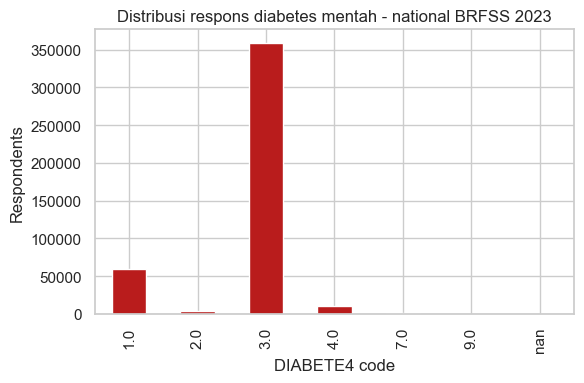

In [3]:
print("DIABETE4 sebelum recoding")
display(raw["DIABETE4"].value_counts(dropna=False).sort_index().rename("n").to_frame())

plt.figure(figsize=(6, 4))
raw["DIABETE4"].value_counts(dropna=False).sort_index().plot(kind="bar", color="#b91c1c")
plt.title("Distribusi respons diabetes mentah - national BRFSS 2023")
plt.xlabel("DIABETE4 code")
plt.ylabel("Respondents")
plt.tight_layout()
plt.show()

## 4. Preprocessing & Outcome

In [4]:
# Paper convention: 1 (diabetes) and 2 (gestational-only) -> positive; 3 (no) and 4 (prediabetes) -> negative.
# Codes 7/9 and missing are excluded.
work = raw.loc[raw["DIABETE4"].isin([1, 2, 3, 4])].copy()
work["diabetes"] = work["DIABETE4"].isin([1, 2]).astype(int)

predictors = [c for c in VARIABLES if c != "DIABETE4"]
for col in predictors:
    work[col] = pd.to_numeric(work[col], errors="coerce")
    work.loc[work[col].isin([7, 9, 77, 88, 99, 777, 888, 999, 7777, 9999]), col] = np.nan

# Paper includes comorbidity/disability burden. Create them only from reported valid binary diagnosis items.
comorbidity_cols = ["BPHIGH6", "TOLDHI3", "HAVARTH4", "CVDINFR4", "CVDSTRK3", "CVDCRHD4"]
disability_cols = ["BLIND", "DEAF", "DECIDE", "DIFFDRES", "DIFFWALK"]
work["comorbidity_count"] = work[comorbidity_cols].eq(1).sum(axis=1)
work["disability_count"] = work[disability_cols].eq(1).sum(axis=1)
predictors += ["comorbidity_count", "disability_count"]

# Paper's Tennessee analysis used n=5,634. The public extract here is national;
# retain a deterministic stratified paper-scale proxy so SVM and all comparators train on the same cohort.
PAPER_SCALE_N = 5_634
if len(work) > PAPER_SCALE_N:
    _, work = train_test_split(
        work,
        test_size=PAPER_SCALE_N / len(work),
        stratify=work["diabetes"],
        random_state=RANDOM_STATE,
    )
    work = work.copy()

X = work[predictors].copy()
y = work["diabetes"].copy()
print(f"Analytical cohort: {len(work):,} respondents")
print(pd.DataFrame({"n": y.value_counts(), "share": y.value_counts(normalize=True).round(4)}).sort_index())

Analytical cohort: 5,634 respondents
             n   share
diabetes              
0         4813  0.8543
1          821  0.1457


## 5. Split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape[0]:,} | Test (untouched): {X_test.shape[0]:,}")
assert set(X_train.index).isdisjoint(set(X_test.index))
assert y_train.mean() > 0 and y_test.mean() > 0

Train: 4,507 | Test (untouched): 1,127


## 6. Encoding

In [6]:
# All BRFSS survey predictors are treated as categorical, as described in the reference paper.
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)
feature_names = preprocessor.named_steps["onehot"].get_feature_names_out(predictors)
print(f"Encoded features: {X_train_encoded.shape[1]}")

Encoded features: 196


## 7. Balancing

In [7]:
# Leakage guard: SMOTE learns only from X_train_encoded/y_train; the held-out test set is never resampled.
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train_encoded, y_train)
print("Train before SMOTE:", y_train.value_counts().to_dict())
print("Train after SMOTE: ", pd.Series(y_train_smote).value_counts().to_dict())
print("Test remains raw:   ", y_test.value_counts().to_dict())
assert len(X_test_encoded) == len(y_test)

Train before SMOTE: {0: 3850, 1: 657}
Train after SMOTE:  {0: 3850, 1: 3850}
Test remains raw:    {0: 963, 1: 164}


  File "C:\Users\akbar\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\akbar\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 546, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\akbar\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1022, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\akbar\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1491, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


## 8. Modelling

In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "SVM": SVC(probability=True, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
        n_jobs=-1, random_state=RANDOM_STATE,
    ),
}

fitted = {}
for name, model in models.items():
    model.fit(X_train_smote, y_train_smote)
    fitted[name] = model
print("Fitted:", list(fitted))

Fitted: ['Logistic Regression', 'SVM', 'KNN', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'XGBoost']


## 9. Evaluation

In [9]:
rows = []
for name, model in fitted.items():
    pred = model.predict(X_test_encoded)
    prob = model.predict_proba(X_test_encoded)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "AUROC": roc_auc_score(y_test, prob),
        "PR-AUC": average_precision_score(y_test, prob),
    })
results = pd.DataFrame(rows).sort_values("AUROC", ascending=False).reset_index(drop=True)
display(results.style.format({c: "{:.4f}" for c in results.columns if c != "Model"}).highlight_max(subset=["AUROC", "PR-AUC", "Recall"], color="#fde68a"))
results.to_csv(OUT_DIR / "model_metrics.csv", index=False)

,Model,Accuracy,Precision,Recall,F1,Balanced Accuracy,AUROC,PR-AUC
0,Gradient Boosting,0.8438,0.4444,0.2927,0.3529,0.6152,0.7876,0.4000
1,Random Forest,0.8598,0.5577,0.1768,0.2685,0.5765,0.7835,0.3954
2,XGBoost,0.8527,0.4875,0.2378,0.3197,0.5976,0.7777,0.3991
3,Logistic Regression,0.7090,0.2887,0.6829,0.4058,0.6982,0.7731,0.3689
4,SVM,0.8270,0.3946,0.3537,0.3730,0.6306,0.7726,0.3887
5,KNN,0.5475,0.2136,0.7866,0.3359,0.6467,0.6808,0.2245
6,Decision Tree,0.7782,0.2500,0.2622,0.2560,0.5641,0.5682,0.1731


## 10. Visualisasi

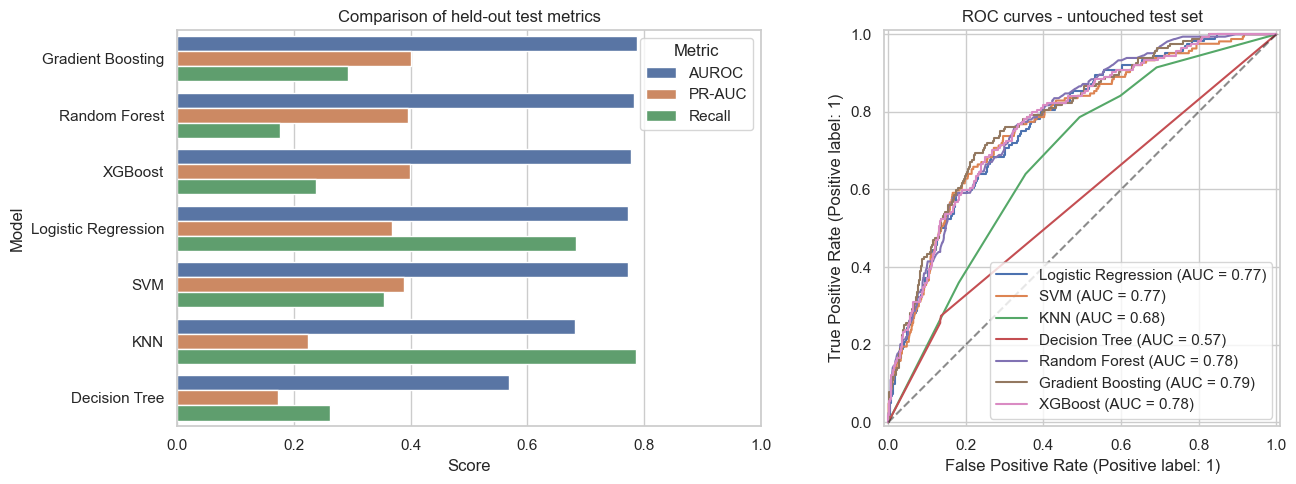

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_df = results.melt(id_vars="Model", value_vars=["AUROC", "PR-AUC", "Recall"], var_name="Metric", value_name="Score")
sns.barplot(data=plot_df, x="Score", y="Model", hue="Metric", ax=axes[0])
axes[0].set_title("Comparison of held-out test metrics")
axes[0].set_xlim(0, 1)

for name, model in fitted.items():
    RocCurveDisplay.from_predictions(y_test, model.predict_proba(X_test_encoded)[:, 1], name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", alpha=.5)
axes[1].set_title("ROC curves - untouched test set")
plt.tight_layout()
plt.savefig(OUT_DIR / "model_comparison_and_roc.png", dpi=180, bbox_inches="tight")
plt.show()

## 11. SHAP

Best by held-out AUROC: Gradient Boosting


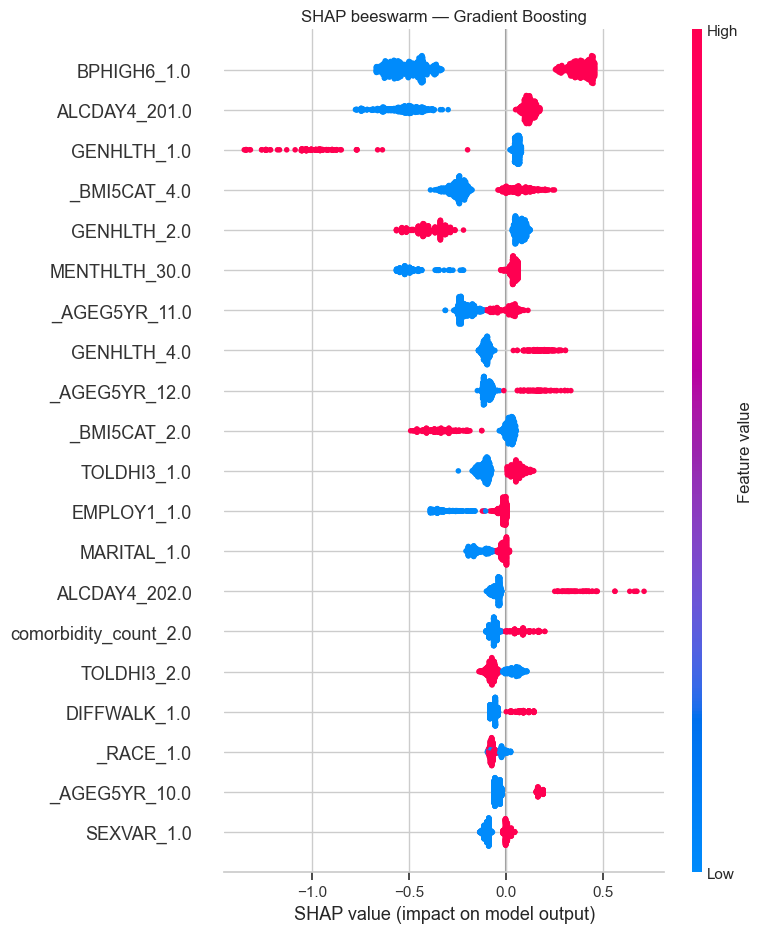

SHAP plot generated successfully.


In [11]:
best_name = results.iloc[0]['Model']
best_model = fitted[best_name]
print('Best by held-out AUROC:', best_name)

try:
    import sys, types
    if 'torch' not in sys.modules:
        sys.modules['torch'] = types.ModuleType('torch')  # mock broken DLL in Windows service session
    import shap
    if best_name in {'Random Forest', 'Gradient Boosting', 'XGBoost', 'Decision Tree'}:
        rng = np.random.default_rng(RANDOM_STATE)
        idx = rng.choice(len(X_test_encoded), size=min(1000, len(X_test_encoded)), replace=False)
        sample = X_test_encoded[idx]
        explainer = shap.TreeExplainer(best_model)
        values = explainer.shap_values(sample)
        if isinstance(values, list):
            values = values[1]
        plt.figure()
        shap.summary_plot(values, sample, feature_names=feature_names, max_display=20, show=False)
        plt.title(f'SHAP beeswarm — {best_name}')
        plt.tight_layout()
        plt.savefig(OUT_DIR / 'shap_beeswarm.png', dpi=180, bbox_inches='tight')
        plt.show()
        print('SHAP plot generated successfully.')
    else:
        print('SHAP TreeExplainer is skipped because the best model is not tree-based.')
except Exception as exc:
    print(f'SHAP skipped due to environment/runtime issue: {type(exc).__name__}: {exc}')


## 12. Reproducibility Record

In [12]:
metadata = {
    "paper_doi": "10.1177/21501319251400546",
    "dataset": "CDC BRFSS 2023 national public-use microdata; deterministic stratified paper-scale proxy n=5,634",
    "split": "80:20 stratified, random_state=42",
    "resampling": "SMOTE on training data only",
    "test_set": "untouched",
    "models": list(models),
    "implementation_note": "Independent implementation from published methods. Paper uses Tennessee; this runnable version uses a stratified national proxy at paper scale because the public extract lacks state code.",
}
(OUT_DIR / "reproducibility.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print(json.dumps(metadata, indent=2))

{
  "paper_doi": "10.1177/21501319251400546",
  "dataset": "CDC BRFSS 2023 national public-use microdata; deterministic stratified paper-scale proxy n=5,634",
  "split": "80:20 stratified, random_state=42",
  "resampling": "SMOTE on training data only",
  "test_set": "untouched",
  "models": [
    "Logistic Regression",
    "SVM",
    "KNN",
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting",
    "XGBoost"
  ],
  "implementation_note": "Independent implementation from published methods. Paper uses Tennessee; this runnable version uses a stratified national proxy at paper scale because the public extract lacks state code."
}
